# heatmap for clusters

In [ ]:
#!/usr/bin/env python3
"""
enrichment_plots_multiplex.py

Same lollipop + heatmap plotting functions as your original script, with
one change: the hardcoded

    hidef_results_file = f"../output/combined26/hidef/hidef_communities.pkl"

block inside both create_persistence_lollipop_plot() and
create_enrichment_heatmap() is replaced by a call to load_persistence_map(),
which can pull persistence from EITHER source:
  - hidef_source='pickle'    -> old monoplex hidef_communities.pkl (unchanged behavior)
  - hidef_source='multiplex' -> new heterogeneous .nodes file, via
                                 hidef_multiplex_adapter.load_multiplex_clusters()

Everything else (tier thresholds, term cleaning, bracket annotations, the
CEMM color palette, etc.) is untouched.
"""

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
from upsetplot import UpSet, from_memberships
import pickle
import re
from hidef_multiplex_adapter import load_multiplex_clusters


In [ ]:


def load_hidef_results(hidef_results_file):
    """Load HiDeF results from pickle file (monoplex pipeline)."""
    if not os.path.exists(hidef_results_file):
        print(f"Error: HiDeF results file not found: {hidef_results_file}")
        return None

    with open(hidef_results_file, 'rb') as f:
        hidef_results = pickle.load(f)

    return hidef_results


def extract_persistent_communities(hidef_results, min_persistence=5):
    """Extract the most persistent communities from HiDeF results (monoplex pipeline)."""
    communities = hidef_results.get('communities', hidef_results)

    persistent_communities = {}
    for comm_id, comm_data in communities.items():
        persistence = comm_data.get('persistence', 0)
        if persistence >= min_persistence:
            persistent_communities[comm_id] = comm_data

    return persistent_communities


def load_persistence_map(hidef_source='pickle',
                          hidef_pickle_file="../output/combined26/hidef/hidef_communities.pkl",
                          nodes_file=None, supra_graph_pkl=None, seed_genes_file=None,
                          persistence_threshold=0):
    """
    Returns {clean_cluster_id: persistence_value} (keys already have the
    "HiDeF_Cluster_" prefix stripped, matching what both plot functions
    expect) regardless of which pipeline produced the clustering.

    hidef_source='pickle'    : reads hidef_pickle_file (old monoplex path)
    hidef_source='multiplex' : reads nodes_file via load_multiplex_clusters()
                                (new heterogeneous pipeline). supra_graph_pkl
                                is only needed if your .nodes members are
                                integer indices rather than "ct::gene"
                                strings; seed_genes_file is optional and only
                                affects the (unused here) seed mapping.
    """
    if hidef_source == 'pickle':
        if not hidef_pickle_file or not os.path.exists(hidef_pickle_file):
            print(f"Error: HiDeF results file not found: {hidef_pickle_file}")
            return None
        hidef_results = load_hidef_results(hidef_pickle_file)
        if hidef_results is None:
            return None
        persistent_communities = extract_persistent_communities(hidef_results, min_persistence=0)
        persistence_map = {}
        for k, v in persistent_communities.items():
            cluster_id = f"HiDeF_Cluster_{k}" if isinstance(k, int) else str(k)
            persistence_map[cluster_id.replace('HiDeF_Cluster_', '')] = v['persistence']
        return persistence_map

    elif hidef_source == 'multiplex':
        if not nodes_file or not os.path.exists(nodes_file):
            print(f"Error: multiplex .nodes file not found: {nodes_file}")
            return None

        node_names = None
        if supra_graph_pkl:
            with open(supra_graph_pkl, 'rb') as f:
                g = pickle.load(f)
            node_names = g.vs['name']

        seed_genes = None
        if seed_genes_file:
            seed_genes = set(pd.read_csv(seed_genes_file)['gene'].astype(str))

        _, _, extra = load_multiplex_clusters(
            nodes_file, node_names=node_names, seed_genes=seed_genes,
            persistence_threshold=persistence_threshold,
        )
        persistence_map = {
            cluster_id.replace('HiDeF_Cluster_', ''): persistence
            for cluster_id, persistence in extra['persistence'].items()
        }
        return persistence_map

    else:
        raise ValueError(f"Unknown hidef_source: {hidef_source!r} (expected 'pickle' or 'multiplex')")


def get_persistence_tiers(persistence_values, percentiles=[90, 75, 50]):
    if not persistence_values:
        return {}

    thresholds = [np.percentile(persistence_values, p) for p in percentiles]
    thresholds.sort(reverse=True)

    print(f"\nPersistence Tier Thresholds (Percentiles {percentiles}):")
    print(f"  90th percentile: {thresholds[0]:.2f}")
    print(f"  75th percentile: {thresholds[1]:.2f}")
    print(f"  50th percentile: {thresholds[2]:.2f}")

    tier_mapping = {}
    for value in persistence_values:
        if value >= thresholds[0]:
            tier_mapping[value] = 'Tier 1 (90th+)'
        elif value >= thresholds[1]:
            tier_mapping[value] = 'Tier 2 (75-90th)'
        elif value >= thresholds[2]:
            tier_mapping[value] = 'Tier 3 (50-75th)'
        else:
            tier_mapping[value] = 'Tier 4 (<50th)'

    return tier_mapping, thresholds


def clean_enrichment_term(term, analysis_type):
    """
    Clean an enrichment term:
    - Remove underscores
    - Strip ORPHA suffix for orphanet terms
    - Add group label in parentheses
    """
    group_label_map = {
        'spatial': 'Spatial',
        'phenotype': 'Phenotype',
        'omim_disease': 'OMIM Disease',
        'omim_ps': 'OMIM PS',
        'orphanet_enrichr': 'Orphanet',
        'proteomics': 'Proteomics',
        'neuropathic_pain': 'Neuropathic Pain',
    }

    term = term.replace('_', ' ')

    if analysis_type == 'orphanet_enrichr':
        term = re.sub(r'\s*ORPHA[:\s]\d+.*$', '', term, flags=re.IGNORECASE).strip()

    group_label = group_label_map.get(analysis_type, analysis_type.replace('_', ' ').title())
    return f"{term} ({group_label})"


def get_enrichment_term_column(df, analysis_type):
    """Get the appropriate enrichment term column based on analysis type."""

    term_mapping = {
        'spatial': 'top_cell_type',
        'omim_disease': 'top_disease',
        'omim_ps': 'phenotypic_series',
        'orphanet_enrichr': 'cluster_top_disease',
        'phenotype': 'top_phenotype',
        'proteomics': 'higher_expression_gender',
        'neuropathic_pain': 'top_expression'
    }

    expected_col = term_mapping.get(analysis_type, 'term')
    available_cols = df.columns.tolist()

    if expected_col in available_cols:
        return expected_col

    fallback_cols = ['top_disease', 'top_phenotype', 'top_cell_type', 'term', 'disease', 'phenotype', 'cell_type']

    for col in fallback_cols:
        if col in available_cols:
            return col

    return None


# ============================================================================
# LOLLIPOP PLOT
# ============================================================================

def create_persistence_lollipop_plot(output_dir, ppi_source, cluster_type='hidef_from_comparison',
                                     analysis_types=['phenotype', 'spatial'],
                                     significance_threshold=0.05,
                                     min_cluster_size=10,
                                     persistence_percentiles=[90, 75, 50],
                                     figsize=(20, 14),
                                     min_persistence_percentile=50,
                                     hidef_source='pickle',
                                     hidef_pickle_file="../output/combined26/hidef/hidef_communities.pkl",
                                     nodes_file=None, supra_graph_pkl=None, seed_genes_file=None,
                                     persistence_threshold=0):
    """
    Create a lollipop chart showing enrichment terms on Y-axis and clusters on X-axis,
    grouped by analysis type with bracket annotations.

    hidef_source / hidef_pickle_file / nodes_file / supra_graph_pkl /
    seed_genes_file / persistence_threshold control where persistence
    comes from -- see load_persistence_map() above. Everything else is
    unchanged from the original script.
    """

    print(f"\n{'='*80}")
    print(f"Creating Persistence-based Lollipop Plot with Phenotype and Spatial Integration")
    print(f"{'='*80}")

    persistence_map = load_persistence_map(
        hidef_source=hidef_source, hidef_pickle_file=hidef_pickle_file,
        nodes_file=nodes_file, supra_graph_pkl=supra_graph_pkl,
        seed_genes_file=seed_genes_file, persistence_threshold=persistence_threshold,
    )
    if persistence_map is None:
        return False

    print(f"Loaded {len(persistence_map)} clusters with persistence data")
    print(f"Sample cluster IDs: {list(persistence_map.keys())[:5]}")

    persistence_values = list(persistence_map.values())
    tier_mapping, thresholds = get_persistence_tiers(persistence_values, persistence_percentiles)
    persistence_map = {k: v for k, v in persistence_map.items() if v >= thresholds[2]}

    # Load enrichment results
    all_enrichments = {}

    for analysis_type in analysis_types:
        if analysis_type == 'spatial':
            results_file = os.path.join(output_dir, ppi_source,
                                       'spatial_analysis_hidef_from_comparison',
                                       'spatial_transcriptomics_hidef_comparison_summarized_results.csv')
        elif analysis_type == 'phenotype':
            results_file = os.path.join(output_dir, ppi_source,
                                       'phenotypes_analysis_hidef_from_comparison',
                                       'phenotype_summarized_results.csv')
        else:
            analysis_dir = os.path.join(output_dir, ppi_source, f'{analysis_type}_analysis_{cluster_type}')
            results_file = os.path.join(analysis_dir, f'{analysis_type}_summarized_results.csv')

        if os.path.exists(results_file):
            df = pd.read_csv(results_file)
            df = df[df['adjusted_p_value'] < significance_threshold]
            if 'cluster_size' in df.columns:
                df = df[df['cluster_size'] >= min_cluster_size]

            term_col = get_enrichment_term_column(df, analysis_type)

            if term_col:
                for _, row in df.iterrows():
                    cluster_id = str(row['cluster_id']).replace('HiDeF_Cluster_', '')
                    raw_term = str(row[term_col])
                    term = clean_enrichment_term(raw_term, analysis_type)

                    if cluster_id not in all_enrichments:
                        all_enrichments[cluster_id] = []

                    all_enrichments[cluster_id].append({
                        'analysis_type': analysis_type,
                        'term': term,
                        'p_value': row['adjusted_p_value'],
                        'fold_enrichment': row.get('mean_fold_enrichment', np.nan)
                    })

            print(f"Loaded enrichments from {analysis_type}: {len(df)} significant results")
            if len(df) > 0:
                print(f"  Sample cluster IDs from {analysis_type}: {df['cluster_id'].unique()[:5]}")
        else:
            print(f"Warning: Results file not found for {analysis_type}: {results_file}")

    def get_persistence_category(persistence, cluster_id, all_enrichments, tier_mapping):
        base_category = tier_mapping.get(persistence, 'Unknown')
        has_phenotype = any(e['analysis_type'] == 'phenotype' for e in all_enrichments.get(cluster_id, []))
        has_spatial = any(e['analysis_type'] == 'spatial' for e in all_enrichments.get(cluster_id, []))
        indicators = ("P" if has_phenotype else "") + ("S" if has_spatial else "")
        return f"{base_category}*({indicators})" if indicators else base_category

    plot_data = []

    print(f"\nDebug Info:")
    print(f"  Persistence map keys (sample): {list(persistence_map.keys())[:5]}")
    print(f"  Enrichments keys (sample): {list(all_enrichments.keys())[:5]}")
    print(f"  Total clusters in persistence_map: {len(persistence_map)}")
    print(f"  Total clusters in all_enrichments: {len(all_enrichments)}")

    for cluster_id, persistence in persistence_map.items():
        if cluster_id in all_enrichments:
            persistence_cat = get_persistence_category(persistence, cluster_id, all_enrichments, tier_mapping)
            for enrichment in all_enrichments[cluster_id]:
                plot_data.append({
                    'cluster_id': cluster_id,
                    'persistence': persistence,
                    'persistence_category': persistence_cat,
                    'analysis_type': enrichment['analysis_type'],
                    'term': enrichment['term'],
                    'p_value': enrichment['p_value'],
                    'fold_enrichment': enrichment.get('fold_enrichment', np.nan)
                })

    if not plot_data:
        print("No enriched clusters found!")
        print(f"\nTroubleshooting:")
        print(f"  - Persistence map has {len(persistence_map)} clusters")
        print(f"  - Enrichments loaded for {len(all_enrichments)} clusters")
        print(f"  - Matching clusters: {len(set(persistence_map.keys()) & set(all_enrichments.keys()))}")
        print(f"  - Persistence map sample keys: {list(persistence_map.keys())[:10]}")
        print(f"  - Enrichments sample keys: {list(all_enrichments.keys())[:10]}")
        return False

    plot_df = pd.DataFrame(plot_data)

    fig, ax = plt.subplots(figsize=figsize)

    persistence_order = ['Tier 4 (<50th)', 'Tier 3 (50-75th)', 'Tier 2 (75-90th)', 'Tier 1 (90th+)']

    colors = {
        'phenotype': '#FF6B6B',
        'spatial': '#1f77b4',
        'omim_disease': '#ff7f0e',
        'omim_ps': '#2ca02c',
        'orphanet_enrichr': '#d62728',
        'proteomics': '#8c564b',
        'neuropathic_pain': '#e377c2'
    }

    clusters_by_persistence = plot_df.groupby('cluster_id').agg({
        'persistence': 'first',
        'persistence_category': 'first'
    }).sort_values('persistence', ascending=False)

    x_pos = 0
    x_labels = []
    x_ticks = []
    cluster_positions = {}
    category_x_positions = {}

    for persistence_cat_base in persistence_order:
        matching_cats = [cat for cat in clusters_by_persistence['persistence_category'].unique()
                         if cat.startswith(persistence_cat_base.split('(')[0])]
        clusters_in_cat = []
        for cat in matching_cats:
            clusters_in_cat.extend(
                clusters_by_persistence[clusters_by_persistence['persistence_category'] == cat].index.tolist()
            )

        if clusters_in_cat:
            cat_x_start = x_pos
            for cluster_id in clusters_in_cat:
                cluster_positions[cluster_id] = x_pos
                x_labels.append(cluster_id)
                x_ticks.append(x_pos)
                x_pos += 1.5
            category_x_positions[persistence_cat_base] = (cat_x_start, x_pos - 1.5)
            x_pos += 1

    y_pos_map = {}
    y_pos = 0
    y_labels = []
    y_ticks = []
    group_y_positions = {}

    for analysis_type in analysis_types:
        terms_for_type = sorted(set(
            row['term'] for _, row in plot_df[plot_df['analysis_type'] == analysis_type].iterrows()
        ))
        if not terms_for_type:
            continue
        group_y_start = y_pos
        for term in terms_for_type:
            term_key = f"{analysis_type}|{term}"
            y_pos_map[term_key] = y_pos
            y_labels.append(term)
            y_ticks.append(y_pos)
            y_pos += 1.0
        group_y_positions[analysis_type] = (group_y_start, y_pos - 1.0)
        y_pos += 1.0

    for cluster_id, x in cluster_positions.items():
        cluster_data = plot_df[plot_df['cluster_id'] == cluster_id]
        for _, row in cluster_data.iterrows():
            term_key = f"{row['analysis_type']}|{row['term']}"
            if term_key not in y_pos_map:
                continue
            y = y_pos_map[term_key]
            analysis_type = row['analysis_type']
            color = colors.get(analysis_type, 'gray')

            ax.plot([0, x], [y, y], color=color, linewidth=1.5, alpha=0.5, zorder=1)
            ax.scatter(x, y, s=150, color=color, zorder=3, edgecolors='black', linewidth=0.8)

    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=14)
    ax.set_xlabel('Clusters (grouped by persistence tier)', fontsize=14, fontweight='bold', labelpad=10)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=14)
    ax.set_ylabel('Enrichment Terms (grouped by analysis type)', fontsize=14, fontweight='bold', labelpad=10)

    for persistence_cat_base, (x_start, x_end) in category_x_positions.items():
        mid_x = (x_start + x_end) / 2
        ax.annotate('', xy=(x_start - 0.3, -2.5), xytext=(x_end + 0.3, -2.5),
                    arrowprops=dict(arrowstyle='-', color='black', lw=1.5))
        ax.text(mid_x, -3.2, persistence_cat_base, ha='center', va='top',
                fontsize=14, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='lightgray', alpha=0.6))

    group_label_map = {
        'spatial': 'Spatial',
        'phenotype': 'Phenotype',
        'omim_disease': 'OMIM Disease',
        'omim_ps': 'OMIM PS',
        'orphanet_enrichr': 'Orphanet',
        'proteomics': 'Proteomics',
        'neuropathic_pain': 'Neuropathic Pain',
    }
    bracket_x = x_pos + 0.5
    for analysis_type, (y_start, y_end) in group_y_positions.items():
        mid_y = (y_start + y_end) / 2
        group_color = colors.get(analysis_type, 'gray')
        group_label = group_label_map.get(analysis_type, analysis_type.replace('_', ' ').title())
        ax.annotate('', xy=(bracket_x, y_start - 0.3), xytext=(bracket_x, y_end + 0.3),
                    arrowprops=dict(arrowstyle='-', color=group_color, lw=2.5))
        ax.text(bracket_x + 0.3, mid_y, group_label, ha='left', va='center',
                fontsize=14, fontweight='bold', color=group_color)

    ax.set_xlim(-1, x_pos + 1)
    ax.set_ylim(-4, y_pos + 1)

    ax.set_title(
        f'Cluster Enrichment by Persistence Tier (Percentiles {persistence_percentiles})\n({ppi_source} - {cluster_type})',
        fontsize=14, fontweight='bold', pad=20
    )

    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=colors[at], label=group_label_map.get(at, at))
                       for at in analysis_types if at in colors]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1),
              fontsize=12, framealpha=0.9,
              title='Analysis Type', title_fontsize=12)

    ax.grid(axis='x', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()

    plot_dir = os.path.join('plots', ppi_source, 'persistence_lollipop')
    Path(plot_dir).mkdir(parents=True, exist_ok=True)

    plot_file = os.path.join(plot_dir, f'persistence_lollipop_{cluster_type}_percentile_tiers.png')
    plt.savefig(plot_file, dpi=300, bbox_inches='tight', facecolor='white')

    pdf_file = plot_file.replace('.png', '.pdf')
    plt.savefig(pdf_file, bbox_inches='tight', facecolor='white')

    plt.show()

    print(f"\nPlot saved to: {plot_file}")
    print(f"PDF saved to: {pdf_file}")

    print(f"\n{'='*60}")
    print("SUMMARY")
    print(f"{'='*60}")
    for persistence_cat in persistence_order:
        matching_cats = [cat for cat in clusters_by_persistence['persistence_category'].unique()
                         if cat.startswith(persistence_cat.split('(')[0])]
        count = sum(len(clusters_by_persistence[clusters_by_persistence['persistence_category'] == cat])
                    for cat in matching_cats)
        if count > 0:
            print(f"Clusters in {persistence_cat}: {count}")

    return True


# ============================================================================
# HEATMAP
# ============================================================================

def load_all_enrichment_results(output_dir, ppi_source, cluster_type, analysis_types):
    """Load all enrichment results from different analysis types."""

    all_results = []

    for analysis_type in analysis_types:
        if analysis_type == 'spatial':
            results_file = os.path.join(output_dir, ppi_source,
                                       'spatial_analysis_hidef_from_comparison',
                                       'spatial_transcriptomics_hidef_comparison_summarized_results.csv')
        elif analysis_type == 'phenotype':
            results_file = os.path.join(output_dir, ppi_source,
                                       'phenotypes_analysis_hidef_from_comparison',
                                       'phenotype_summarized_results.csv')
        else:
            analysis_dir = os.path.join(output_dir, ppi_source, f'{analysis_type}_analysis_{cluster_type}')
            results_file = os.path.join(analysis_dir, f'{analysis_type}_summarized_results.csv')

        if os.path.exists(results_file):
            df = pd.read_csv(results_file)
            df['analysis_type'] = analysis_type
            all_results.append(df)
            print(f"Loaded {len(df)} results from {analysis_type}")
        else:
            print(f"Warning: Results file not found for {analysis_type}: {results_file}")

    if not all_results:
        print("No results files found!")
        return None

    combined_df = pd.concat(all_results, ignore_index=True)
    print(f"\nTotal combined results: {len(combined_df)} rows across {len(analysis_types)} analysis types")

    return combined_df


def get_enrichment_term_column_heatmap(df, analysis_type):
    """Get the appropriate enrichment term column based on analysis type for heatmap."""

    term_mapping = {
        'spatial': 'top_cell_type',
        'omim_disease': 'top_disease',
        'omim_ps': 'phenotypic_series',
        'orphanet_enrichr': 'cluster_top_disease',
        'phenotype': 'top_phenotype',
        'proteomics': 'higher_expression_gender',
        'neuropathic_pain': 'top_expression'
    }

    if analysis_type in ['proteomics', 'neuropathic_pain']:
        actual_col = term_mapping.get(analysis_type)
        available_cols = df.columns.tolist()
        if actual_col and actual_col in available_cols:
            return actual_col
        return None

    expected_col = term_mapping.get(analysis_type, 'term')
    available_cols = df.columns.tolist()

    if expected_col in available_cols:
        return expected_col

    fallback_cols = ['top_disease', 'top_phenotype', 'top_cell_type', 'term', 'disease', 'phenotype', 'cell_type']

    for col in fallback_cols:
        if col in available_cols:
            print(f"Using fallback column '{col}' for {analysis_type}")
            return col

    print(f"Warning: No suitable term column found for {analysis_type}")
    return None


def create_enrichment_heatmap(output_dir, ppi_source, cluster_type='hidef_from_comparison',
                            analysis_types=['phenotype', 'spatial'],
                            value_col='mean_log_fold_change',
                            significance_col='adjusted_p_value',
                            significance_threshold=0.05,
                            min_cluster_size=10,
                            figsize=(16, 12),
                            min_persistence_percentile=50,
                            hidef_source='pickle',
                            hidef_pickle_file="../output/combined26/hidef/hidef_communities.pkl",
                            nodes_file=None, supra_graph_pkl=None, seed_genes_file=None,
                            persistence_threshold=0):
    """
    Create a comprehensive heatmap of enrichment results across analysis types,
    including phenotype and spatial enrichments.

    hidef_source / hidef_pickle_file / nodes_file / supra_graph_pkl /
    seed_genes_file / persistence_threshold control where persistence
    comes from -- see load_persistence_map() above. Everything else is
    unchanged from the original script.
    """

    print(f"\n{'='*80}")
    print(f"Creating Enrichment Heatmap with Phenotype and Spatial Integration")
    print(f"{'='*80}")

    persistence_map = load_persistence_map(
        hidef_source=hidef_source, hidef_pickle_file=hidef_pickle_file,
        nodes_file=nodes_file, supra_graph_pkl=supra_graph_pkl,
        seed_genes_file=seed_genes_file, persistence_threshold=persistence_threshold,
    )
    if persistence_map is None:
        return False

    print(f"Loaded {len(persistence_map)} clusters with persistence data")
    print(f"Sample cluster IDs: {list(persistence_map.keys())[:5]}")

    persistence_percentiles = [90, 75, 50]

    persistence_values = list(persistence_map.values())
    tier_mapping, thresholds = get_persistence_tiers(persistence_values, persistence_percentiles)
    persistence_map = {k: v for k, v in persistence_map.items() if v >= thresholds[2]}
    p50 = np.percentile(list(persistence_map.values()), min_persistence_percentile)
    valid_clusters = {k for k, v in persistence_map.items() if v >= p50}

    combined_df = load_all_enrichment_results(output_dir, ppi_source, cluster_type, analysis_types)

    if combined_df is None:
        return False

    print(f"\nFiltering results...")
    print(f"Before filtering: {len(combined_df)} rows")

    if significance_col in combined_df.columns:
        significant_df = combined_df[combined_df[significance_col] < significance_threshold].copy()
        print(f"After significance filter ({significance_col} < {significance_threshold}): {len(significant_df)} rows")
    else:
        significant_df = combined_df.copy()
        print(f"Warning: {significance_col} column not found, skipping significance filter")

    if 'cluster_size' in significant_df.columns:
        significant_df = significant_df[significant_df['cluster_size'] >= min_cluster_size].copy()
        print(f"After cluster size filter (>= {min_cluster_size}): {len(significant_df)} rows")

    significant_df = significant_df[significant_df['cluster_id'].astype(str)
                                    .str.replace('HiDeF_Cluster_', '').isin(valid_clusters)]

    if len(significant_df) == 0:
        print("No significant results found after filtering!")
        return False

    group_label_map = {
        'spatial': 'Spatial',
        'phenotype': 'Phenotype',
        'omim_disease': 'OMIM Disease',
        'omim_ps': 'OMIM PS',
        'orphanet_enrichr': 'Orphanet',
        'proteomics': 'Proteomics',
        'neuropathic_pain': 'Neuropathic Pain',
    }

    heatmap_data = []

    for analysis_type in analysis_types:
        analysis_df = significant_df[significant_df['analysis_type'] == analysis_type].copy()

        if len(analysis_df) == 0:
            continue

        term_col = get_enrichment_term_column_heatmap(analysis_df, analysis_type)

        if term_col is None:
            continue

        group_label = group_label_map.get(analysis_type, analysis_type.replace('_', ' ').title())

        def build_term(raw, atype):
            t = str(raw).replace('_', ' ').replace('nan', '').strip()
            if atype == 'orphanet_enrichr':
                t = re.sub(r'\s*ORPHA[:\s]\d+.*$', '', t, flags=re.IGNORECASE).strip()
            lbl = group_label_map.get(atype, atype.replace('_', ' ').title())
            return f"{t} ({lbl})" if t else ''

        analysis_df['enrichment_term'] = analysis_df[term_col].apply(lambda x: build_term(x, analysis_type))

        if 'cluster_id' not in analysis_df.columns:
            print(f"Warning: cluster_id column not found for {analysis_type}")
            continue

        for _, row in analysis_df.iterrows():
            if not row['enrichment_term'] or row['enrichment_term'] in ['', 'nan', 'NaN', f' ({group_label})']:
                continue

            cluster_name = str(row['cluster_id']).replace('HiDeF_Cluster_', '').replace('Community_', '')

            heatmap_data.append({
                'cluster_name': cluster_name,
                'enrichment_term': row['enrichment_term'],
                'analysis_type': analysis_type,
                'value': row[value_col] if value_col in row else np.nan,
                'p_value': row.get(significance_col, np.nan),
                'cluster_size': row.get('cluster_size', np.nan),
                'seed_gene_count': row.get('seed_gene_count_in_cluster', np.nan)
            })

    if not heatmap_data:
        print("No data available for heatmap!")
        return False

    heatmap_df = pd.DataFrame(heatmap_data)
    print(f"\nHeatmap data shape: {heatmap_df.shape}")
    print(f"Unique clusters: {heatmap_df['cluster_name'].nunique()}")
    print(f"Unique terms: {heatmap_df['enrichment_term'].nunique()}")

    if value_col == 'mean_log_fold_change':
        max_finite = heatmap_df[heatmap_df['value'] != np.inf]['value'].max()
        if pd.isna(max_finite):
            max_finite = 10
        heatmap_df['value'] = heatmap_df['value'].replace([np.inf, -np.inf], [max_finite * 2, -max_finite * 2])
        heatmap_df['value'] = heatmap_df['value'] * 10
    elif 'p_value' in value_col:
        heatmap_df['value'] = -np.log10(heatmap_df['value'].clip(lower=1e-10))
    else:
        if heatmap_df['value'].min() >= 0:
            heatmap_df['value'] = np.sqrt(heatmap_df['value'])
        else:
            heatmap_df['value'] = np.sign(heatmap_df['value']) * np.power(np.abs(heatmap_df['value']), 1/3)

    heatmap_df_agg = heatmap_df.groupby(['enrichment_term', 'cluster_name'])['value'].mean().reset_index()
    pivot_df = heatmap_df_agg.pivot(index='enrichment_term', columns='cluster_name', values='value')
    print(f"Pivot table shape: {pivot_df.shape}")

    pivot_df = pivot_df.dropna(axis=0, how='all')
    pivot_df = pivot_df.dropna(axis=1, how='all')

    if pivot_df.empty:
        print("No data remaining after removing empty rows and columns!")
        return False

    print(f"Pivot table shape after removing empty rows/columns: {pivot_df.shape}")

    cemm_colors = {
        'blue': '#00AECC',
        'medium_blue': '#1B88A7',
        'dark_blue': '#0F5569',
        'light_blue': '#BEE3EF',
        'pink': '#C73188',
        'orange': '#E95E30',
        'yellow': '#F1DD00',
        'green': '#96C03A',
        'red': '#FF6B6B'
    }

    if value_col in ['mean_log_fold_change', 'log_fold_change']:
        colors_list = [cemm_colors['dark_blue'], cemm_colors['medium_blue'], cemm_colors['light_blue'],
                 'white', cemm_colors['yellow'], cemm_colors['orange'], cemm_colors['pink']]
        cmap = sns.blend_palette(colors_list, n_colors=256, as_cmap=True)
        center = 0
        cbar_label = f'{value_col.replace("_", " ").title()} (×10)'
    elif 'p_value' in value_col:
        colors_list = [cemm_colors['light_blue'], cemm_colors['blue'], cemm_colors['dark_blue']]
        cmap = sns.blend_palette(colors_list, n_colors=256, as_cmap=True)
        center = None
        cbar_label = f'-log10({value_col.replace("_", " ").title()})'
    else:
        colors_list = [cemm_colors['light_blue'], cemm_colors['blue'], cemm_colors['medium_blue'],
                 cemm_colors['dark_blue'], cemm_colors['pink']]
        cmap = sns.blend_palette(colors_list, n_colors=256, as_cmap=True)
        center = None
        cbar_label = f'Transformed {value_col.replace("_", " ").title()}'

    plt.figure(figsize=figsize)

    if value_col in ['mean_log_fold_change', 'log_fold_change']:
        vmin = 3
        vmax = 3.5
        center = 4
    elif value_col in ['mean_odds_ratio']:
        vmin = 0.10
        vmax = 0.12
        center = 0.13
    else:
        vmin = None
        vmax = None

    ax = sns.heatmap(pivot_df,
                     cmap=cmap,
                     center=center,
                     vmin=vmin,
                     vmax=vmax,
                     cbar_kws={'label': cbar_label},
                     linewidths=0.5,
                     linecolor='white',
                     square=False,
                     xticklabels=True,
                     yticklabels=True)

    ax.tick_params(axis='x', labelsize=20)
    ax.tick_params(axis='y', labelsize=20)
    ax.figure.axes[-1].tick_params(labelsize=20)

    plt.title(f'Cluster Enrichment Heatmap with Phenotype and Spatial Integration\n({ppi_source} - {cluster_type})',
              fontsize=20, fontweight='bold', pad=20)

    plt.xlabel('Clusters', fontsize=20, fontweight='bold')
    plt.ylabel('Enrichment Terms', fontsize=20, fontweight='bold')

    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    plt.tight_layout()

    plot_dir = os.path.join('plots', ppi_source, 'enrichment_heatmaps')
    Path(plot_dir).mkdir(parents=True, exist_ok=True)

    plot_file = os.path.join(plot_dir, f'enrichment_heatmap_{cluster_type}_{value_col}_phenotype_spatial.png')
    plt.savefig(plot_file, dpi=300, bbox_inches='tight', facecolor='white')

    pdf_file = plot_file.replace('.png', '.pdf')
    plt.savefig(pdf_file, bbox_inches='tight', facecolor='white')

    plt.show()

    print(f"\n{'='*60}")
    print("HEATMAP COMPLETE")
    print(f"{'='*60}")
    print(f"Saved heatmap to: {plot_file}")
    print(f"Saved PDF to: {pdf_file}")
    print(f"Clusters visualized: {pivot_df.shape[0]}")
    print(f"Enrichment terms: {pivot_df.shape[1]}")

    print(f"\nSummary by analysis type:")
    for analysis_type in analysis_types:
        count = heatmap_df[heatmap_df['analysis_type'] == analysis_type].shape[0]
        if count > 0:
            print(f"  {analysis_type}: {count} clusters")

    return True


Creating Enrichment Heatmap with Phenotype and Spatial Integration
Loaded 40 clusters with persistence data
Sample cluster IDs: ['0', '1', '2', '3', '4']

Persistence Tier Thresholds (Percentiles [90, 75, 50]):
  90th percentile: 31.70
  75th percentile: 17.00
  50th percentile: 7.00
Loaded 18 results from neuropathic_pain
Loaded 979 results from omim_ps
Loaded 40 results from orphanet_enrichr
Loaded 35 results from phenotype
Loaded 7 results from proteomics
Loaded 40 results from spatial

Total combined results: 1119 rows across 6 analysis types

Filtering results...
Before filtering: 1119 rows
After significance filter (adjusted_p_value < 0.05): 89 rows
After cluster size filter (>= 10): 68 rows
Using fallback column 'top_phenotype' for orphanet_enrichr

Heatmap data shape: (20, 7)
Unique clusters: 9
Unique terms: 11
Pivot table shape: (11, 9)
No data remaining after removing empty rows and columns!

Creating Enrichment Heatmap with Phenotype and Spatial Integration
Loaded 40 cluste

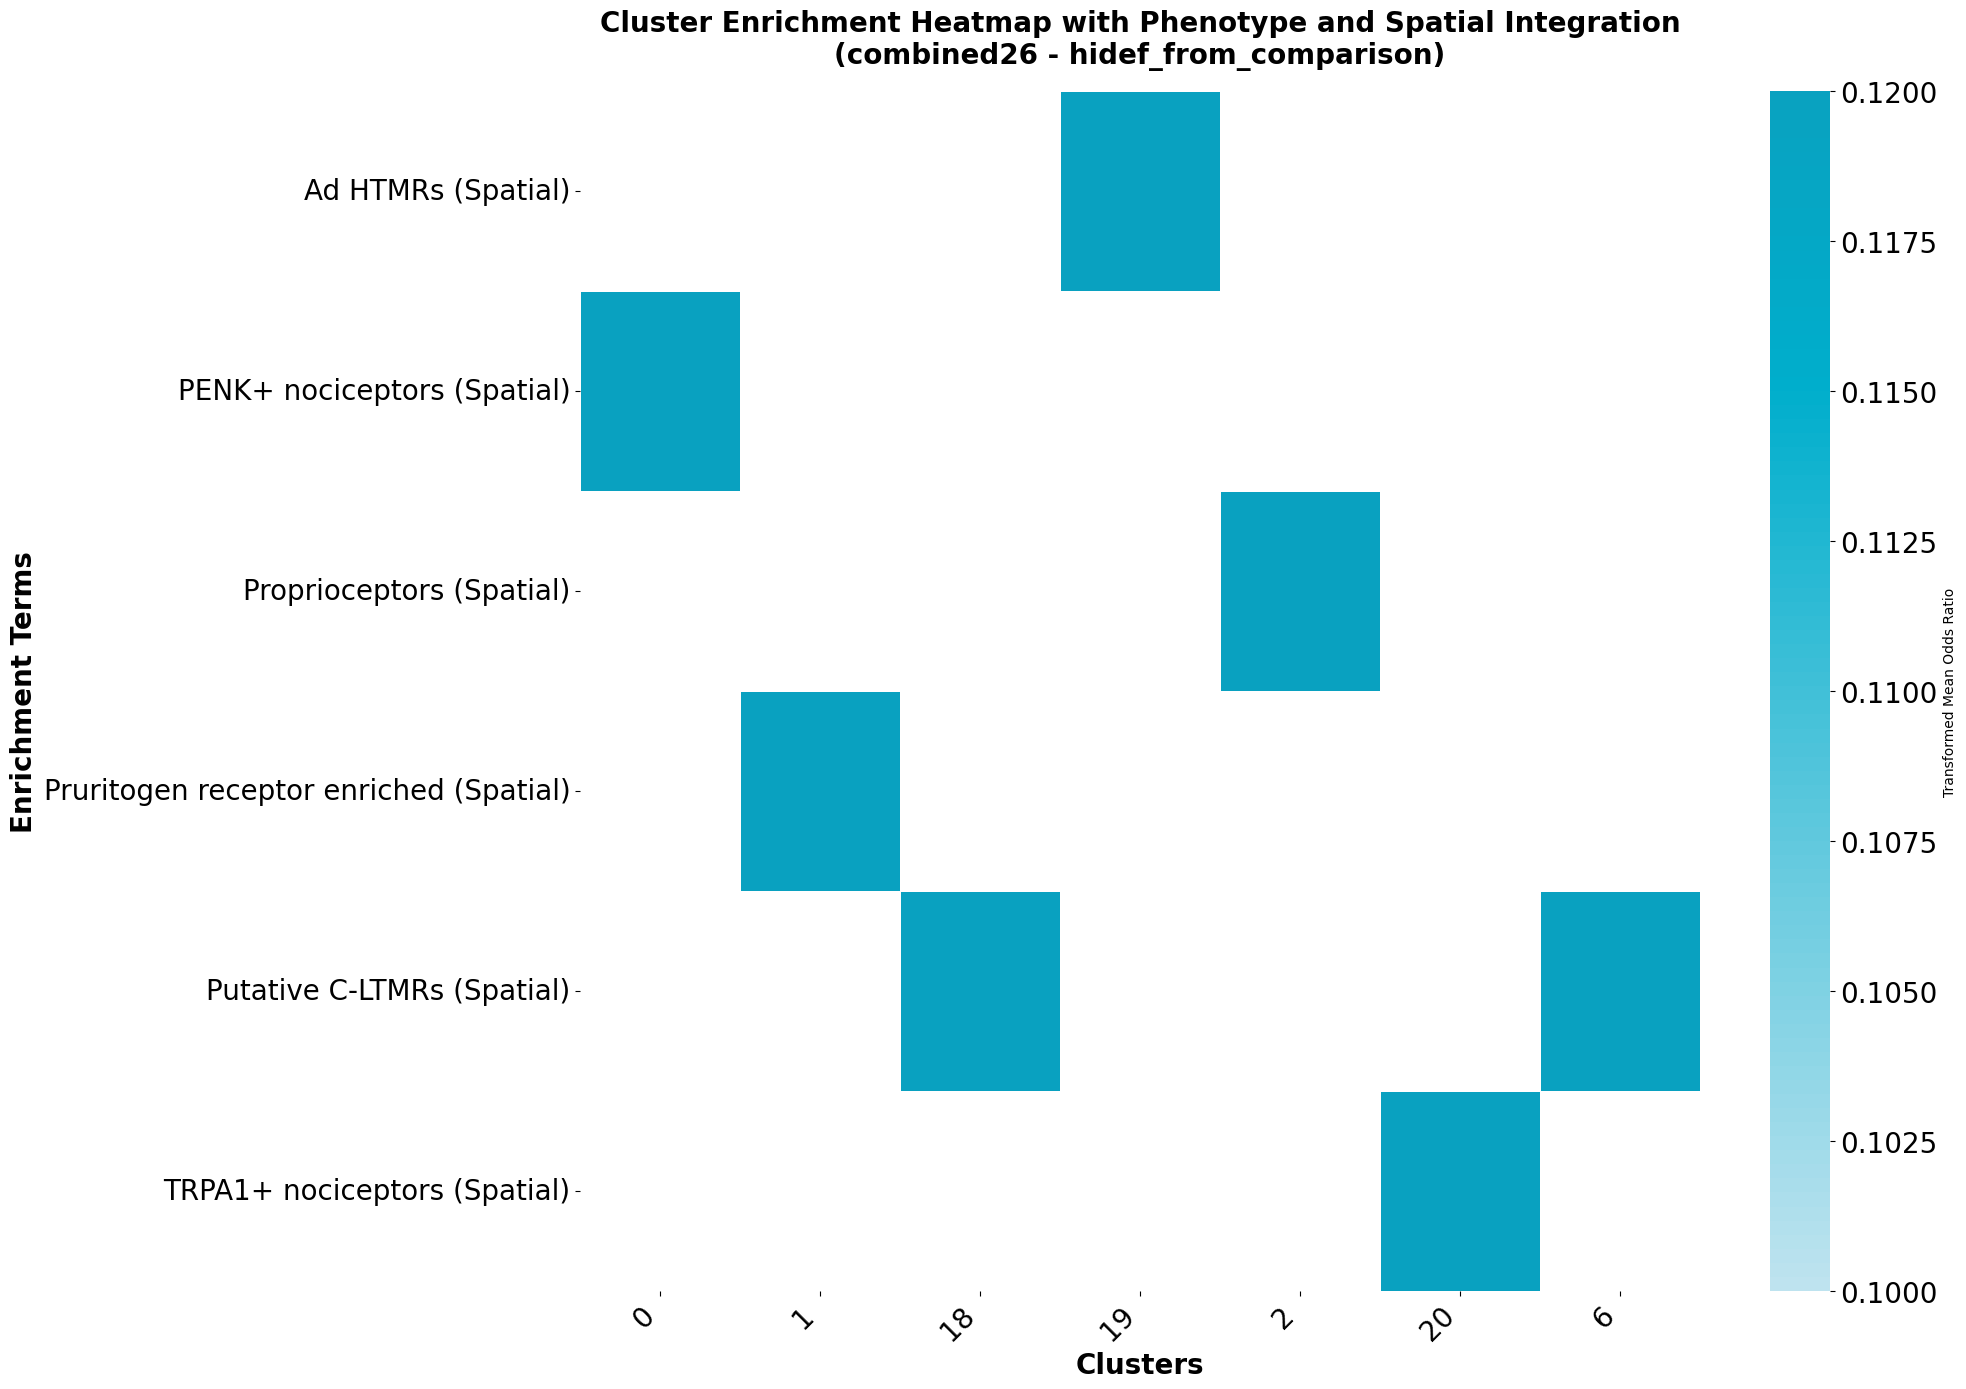


HEATMAP COMPLETE
Saved heatmap to: plots/combined26/enrichment_heatmaps/enrichment_heatmap_hidef_from_comparison_mean_odds_ratio_phenotype_spatial.png
Saved PDF to: plots/combined26/enrichment_heatmaps/enrichment_heatmap_hidef_from_comparison_mean_odds_ratio_phenotype_spatial.pdf
Clusters visualized: 6
Enrichment terms: 7

Summary by analysis type:
  neuropathic_pain: 6 clusters
  phenotype: 3 clusters
  proteomics: 4 clusters
  spatial: 7 clusters

Creating Enrichment Heatmap with Phenotype and Spatial Integration
Loaded 40 clusters with persistence data
Sample cluster IDs: ['0', '1', '2', '3', '4']

Persistence Tier Thresholds (Percentiles [90, 75, 50]):
  90th percentile: 31.70
  75th percentile: 17.00
  50th percentile: 7.00
Loaded 18 results from neuropathic_pain
Loaded 979 results from omim_ps
Loaded 40 results from orphanet_enrichr
Loaded 35 results from phenotype
Loaded 7 results from proteomics
Loaded 40 results from spatial

Total combined results: 1119 rows across 6 analysi

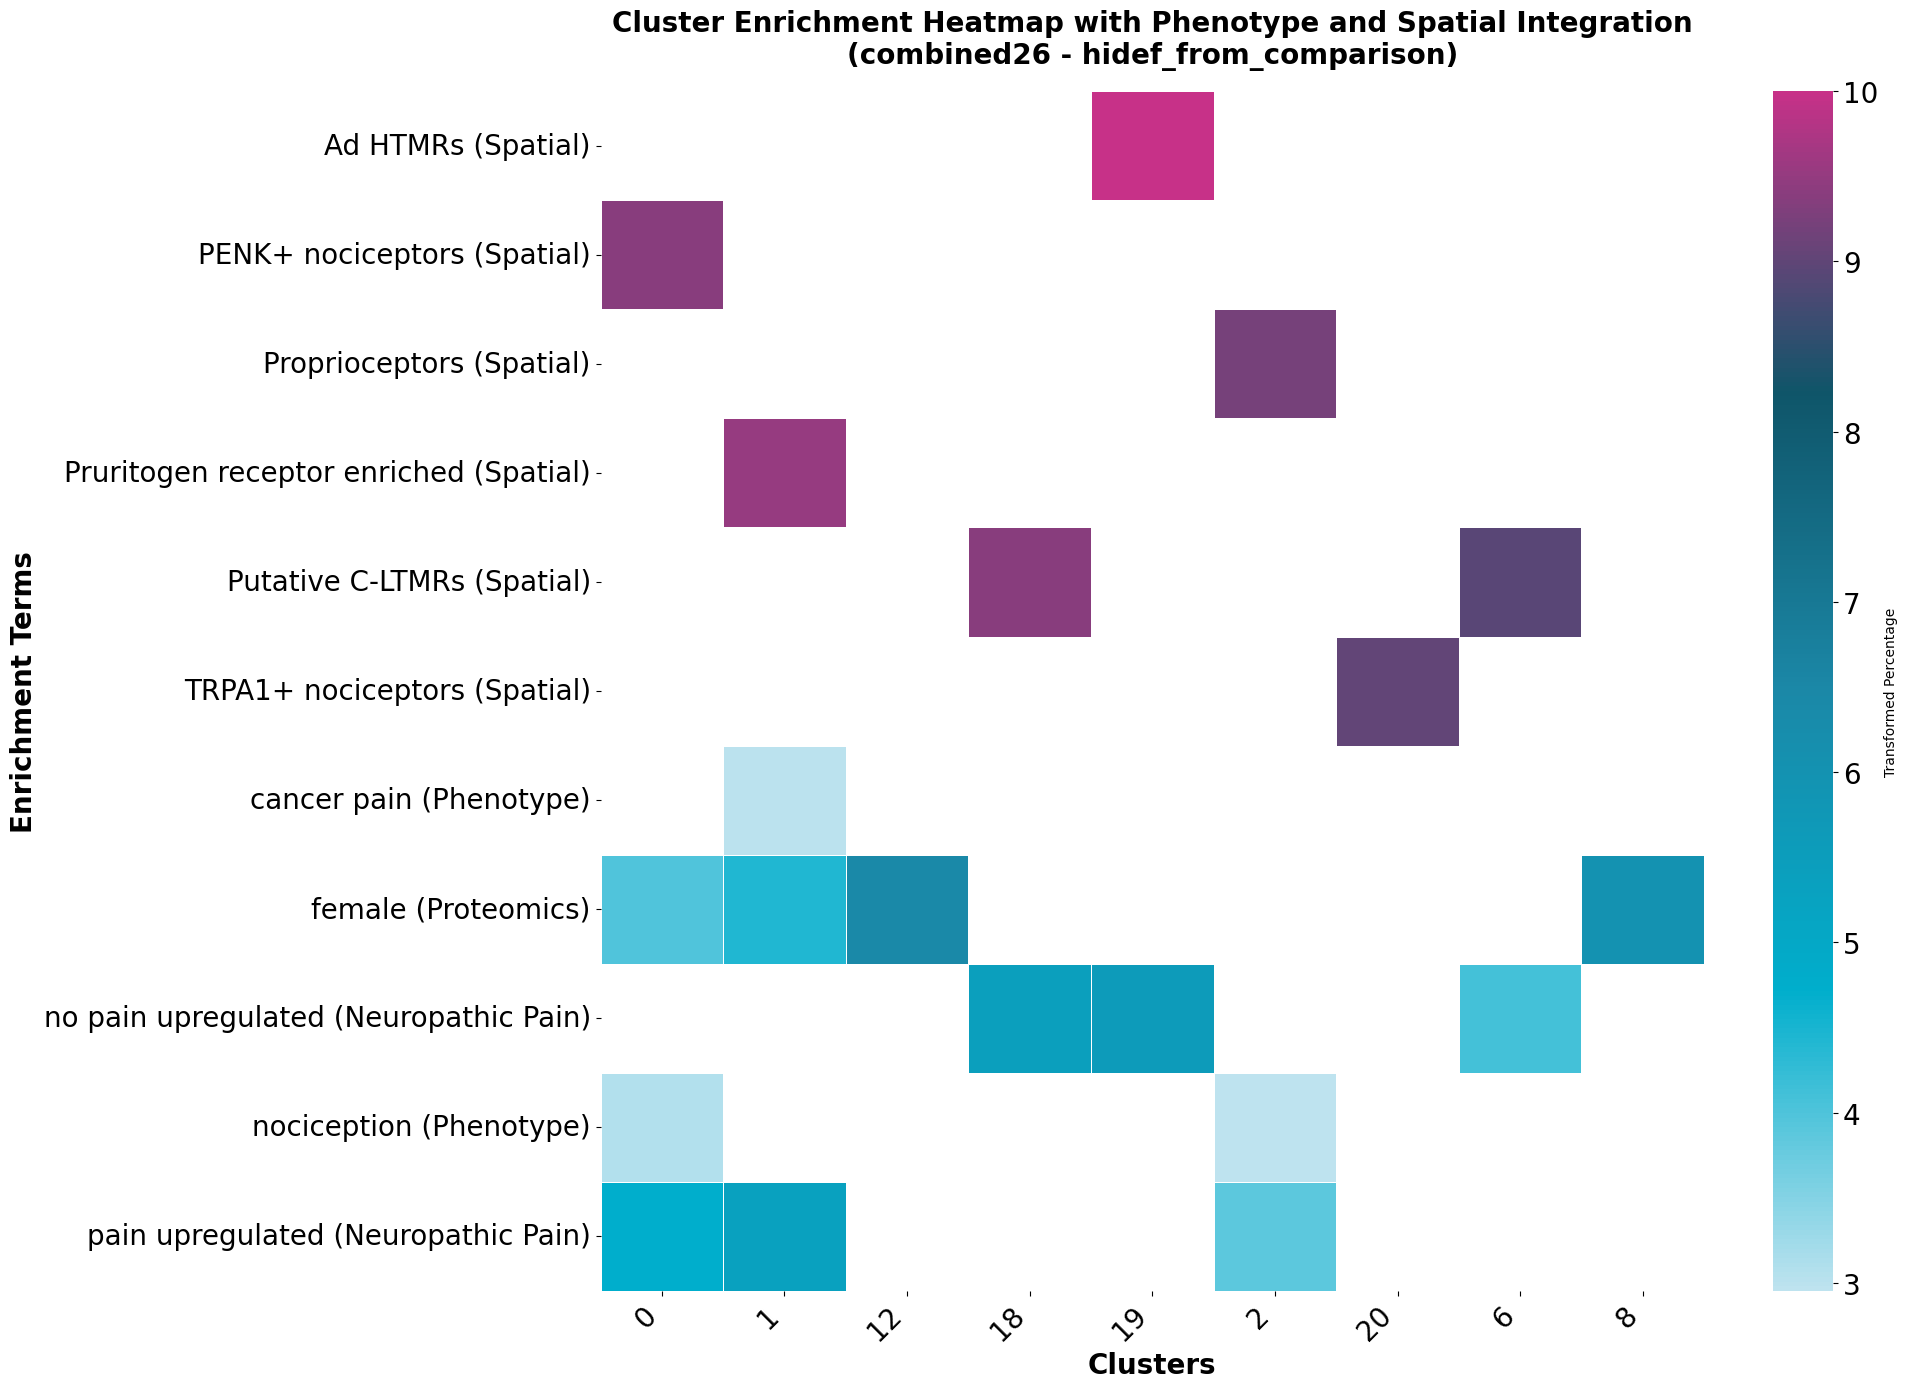


HEATMAP COMPLETE
Saved heatmap to: plots/combined26/enrichment_heatmaps/enrichment_heatmap_hidef_from_comparison_percentage_phenotype_spatial.png
Saved PDF to: plots/combined26/enrichment_heatmaps/enrichment_heatmap_hidef_from_comparison_percentage_phenotype_spatial.pdf
Clusters visualized: 11
Enrichment terms: 9

Summary by analysis type:
  neuropathic_pain: 6 clusters
  phenotype: 3 clusters
  proteomics: 4 clusters
  spatial: 7 clusters


In [5]:
# Parameters (same as your visualization script)
ppi_source = 'combined26'
analysis_types = ['neuropathic_pain', 'omim_ps', 'orphanet_enrichr', 
                 'phenotype', 'proteomics', 'spatial']
output_dir = './output'
cluster_type = 'hidef_from_comparison'

# Create heatmap using log fold change
success1 = create_enrichment_heatmap(
    output_dir=output_dir,
    ppi_source=ppi_source,
    cluster_type=cluster_type,
    analysis_types=analysis_types,
    value_col='mean_log_fold_change',
    significance_threshold=0.05,
    min_cluster_size=10,
    figsize=(20, 14)
)

# Create heatmap using log fold change
success3 = create_enrichment_heatmap(
    output_dir=output_dir,
    ppi_source=ppi_source,
    cluster_type=cluster_type,
    analysis_types=analysis_types,
    value_col='mean_odds_ratio',
    significance_threshold=0.05,
    min_cluster_size=10,
    figsize=(20, 14)
)

# Create heatmap using log fold change
success3 = create_enrichment_heatmap(
    output_dir=output_dir,
    ppi_source=ppi_source,
    cluster_type=cluster_type,
    analysis_types=analysis_types,
    value_col='percentage',
    significance_threshold=0.05,
    min_cluster_size=10,
    figsize=(20, 14)
)



Creating Enrichment Heatmap with Phenotype and Spatial Integration
Loaded 40 clusters with persistence data
Sample cluster IDs: ['0', '1', '2', '3', '4']

Persistence Tier Thresholds (Percentiles [90, 75, 50]):
  90th percentile: 31.70
  75th percentile: 17.00
  50th percentile: 7.00
Loaded 18 results from neuropathic_pain
Loaded 979 results from omim_ps
Loaded 40 results from orphanet_enrichr
Loaded 35 results from phenotype
Loaded 7 results from proteomics
Loaded 40 results from spatial

Total combined results: 1119 rows across 6 analysis types

Filtering results...
Before filtering: 1119 rows
After significance filter (adjusted_p_value < 0.05): 89 rows
After cluster size filter (>= 10): 68 rows
Using fallback column 'top_phenotype' for orphanet_enrichr

Heatmap data shape: (20, 7)
Unique clusters: 9
Unique terms: 11
Pivot table shape: (11, 9)
Pivot table shape after removing empty rows/columns: (11, 9)


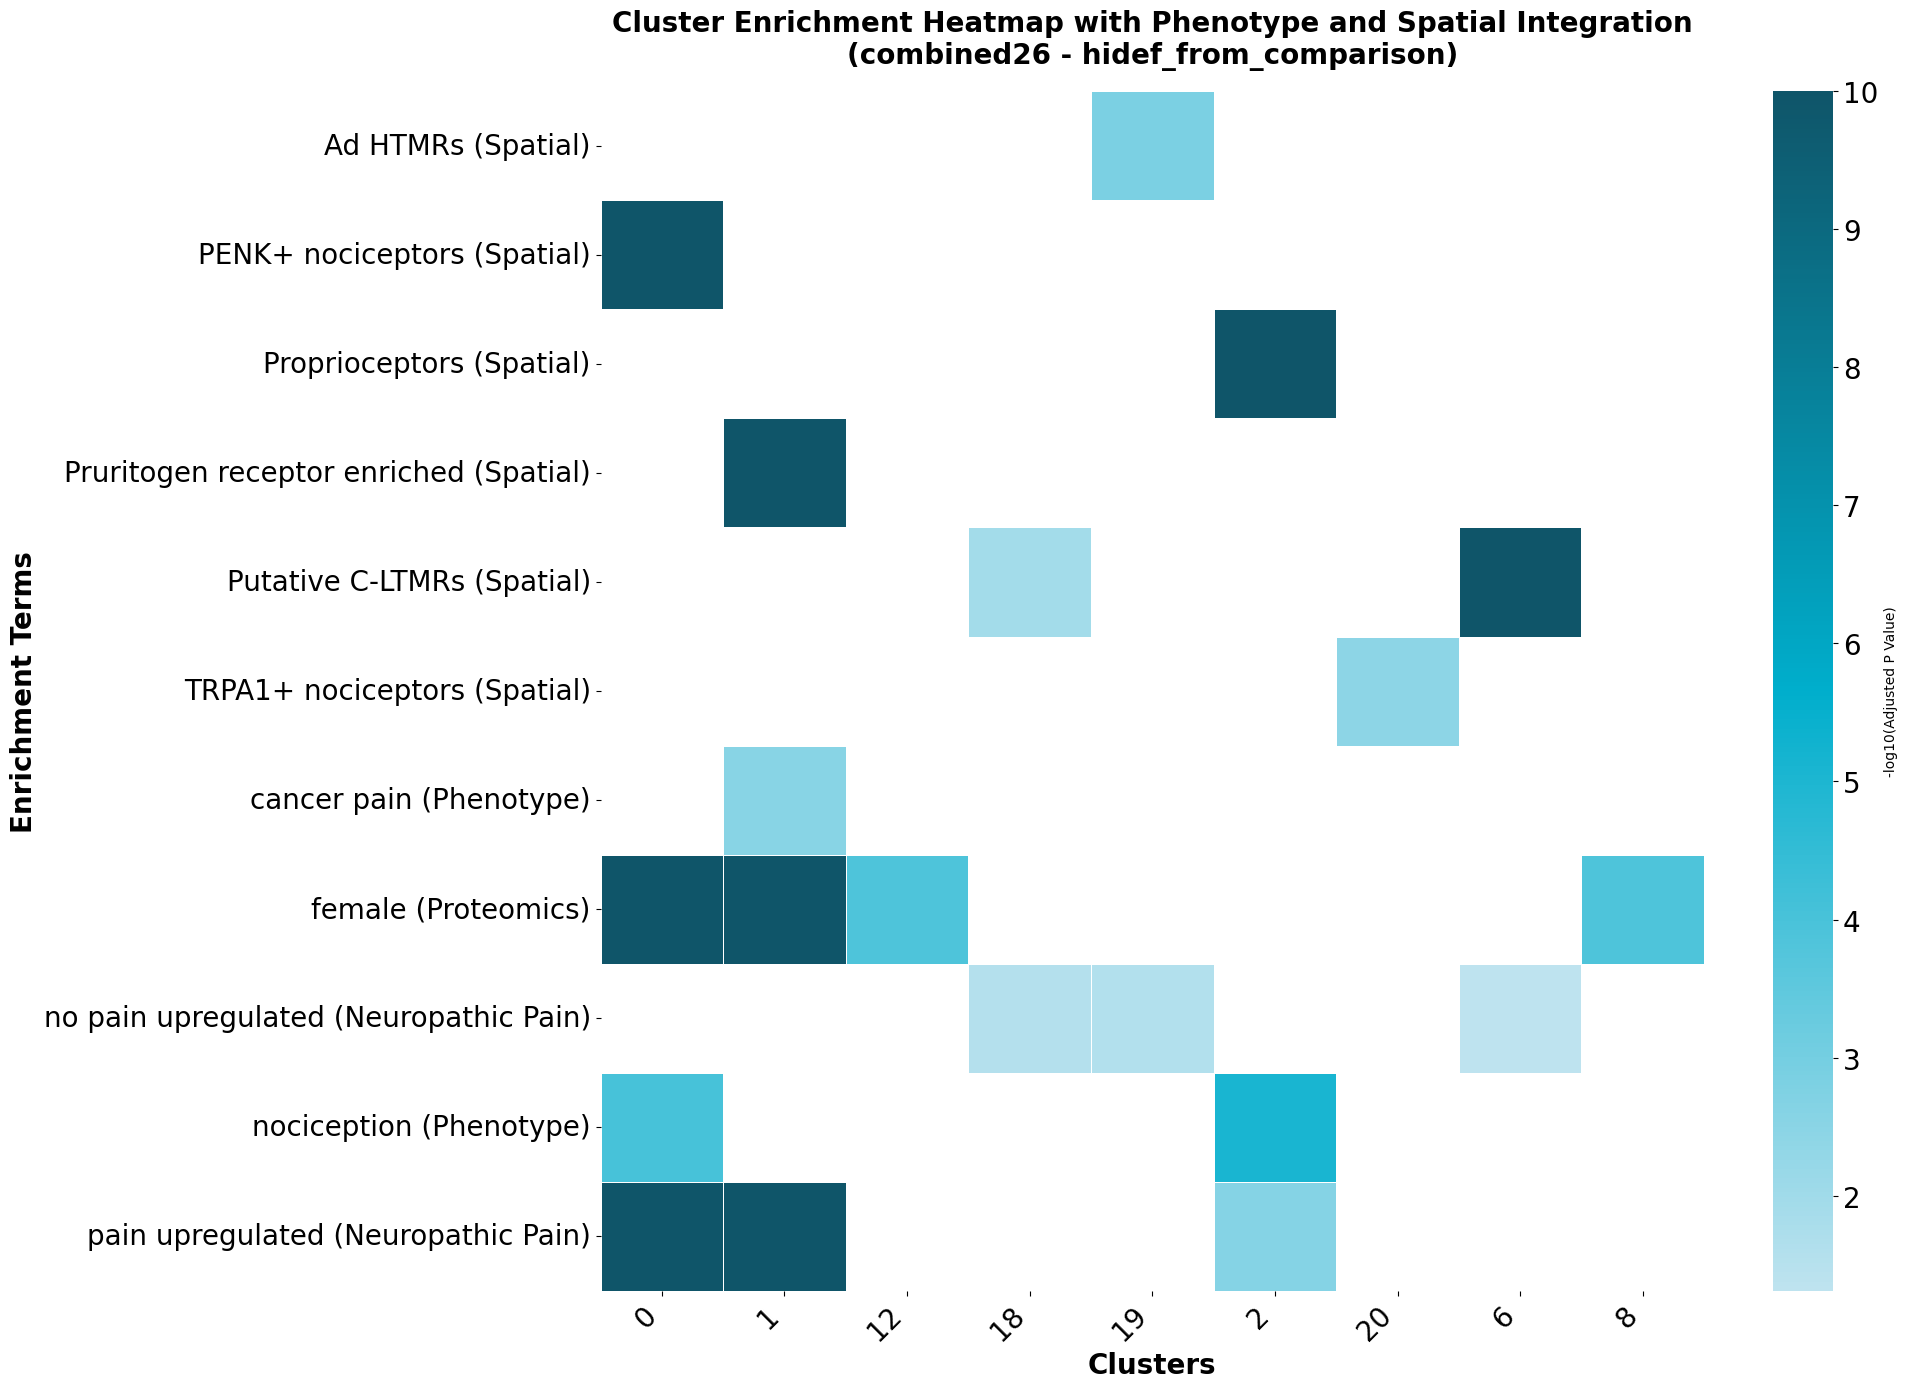


HEATMAP COMPLETE
Saved heatmap to: plots/combined26/enrichment_heatmaps/enrichment_heatmap_hidef_from_comparison_adjusted_p_value_phenotype_spatial.png
Saved PDF to: plots/combined26/enrichment_heatmaps/enrichment_heatmap_hidef_from_comparison_adjusted_p_value_phenotype_spatial.pdf
Clusters visualized: 11
Enrichment terms: 9

Summary by analysis type:
  neuropathic_pain: 6 clusters
  phenotype: 3 clusters
  proteomics: 4 clusters
  spatial: 7 clusters


In [6]:
# Also create a p-value heatmap
success2 = create_enrichment_heatmap(
    output_dir=output_dir,
    ppi_source=ppi_source,
    cluster_type=cluster_type,
    analysis_types=analysis_types,
    value_col='adjusted_p_value',
    significance_threshold=0.05,
    min_cluster_size=10,
    figsize=(20, 14)
)


## Upset Plot


Creating Persistence-based Lollipop Plot with Phenotype and Spatial Integration
Loaded 40 clusters with persistence data
Sample cluster IDs: ['0', '1', '2', '3', '4']

Persistence Tier Thresholds (Percentiles [90, 75, 50]):
  90th percentile: 31.70
  75th percentile: 17.00
  50th percentile: 7.00
Loaded enrichments from neuropathic_pain: 15 significant results
  Sample cluster IDs from neuropathic_pain: <ArrowStringArray>
['HiDeF_Cluster_0', 'HiDeF_Cluster_1', 'HiDeF_Cluster_2', 'HiDeF_Cluster_3',
 'HiDeF_Cluster_4']
Length: 5, dtype: str
Loaded enrichments from omim_ps: 4 significant results
  Sample cluster IDs from omim_ps: <ArrowStringArray>
['HiDeF_Cluster_15', 'HiDeF_Cluster_21']
Length: 2, dtype: str
Loaded enrichments from orphanet_enrichr: 20 significant results
  Sample cluster IDs from orphanet_enrichr: <ArrowStringArray>
['HiDeF_Cluster_0', 'HiDeF_Cluster_1', 'HiDeF_Cluster_2', 'HiDeF_Cluster_3',
 'HiDeF_Cluster_4']
Length: 5, dtype: str
Loaded enrichments from phenotype: 

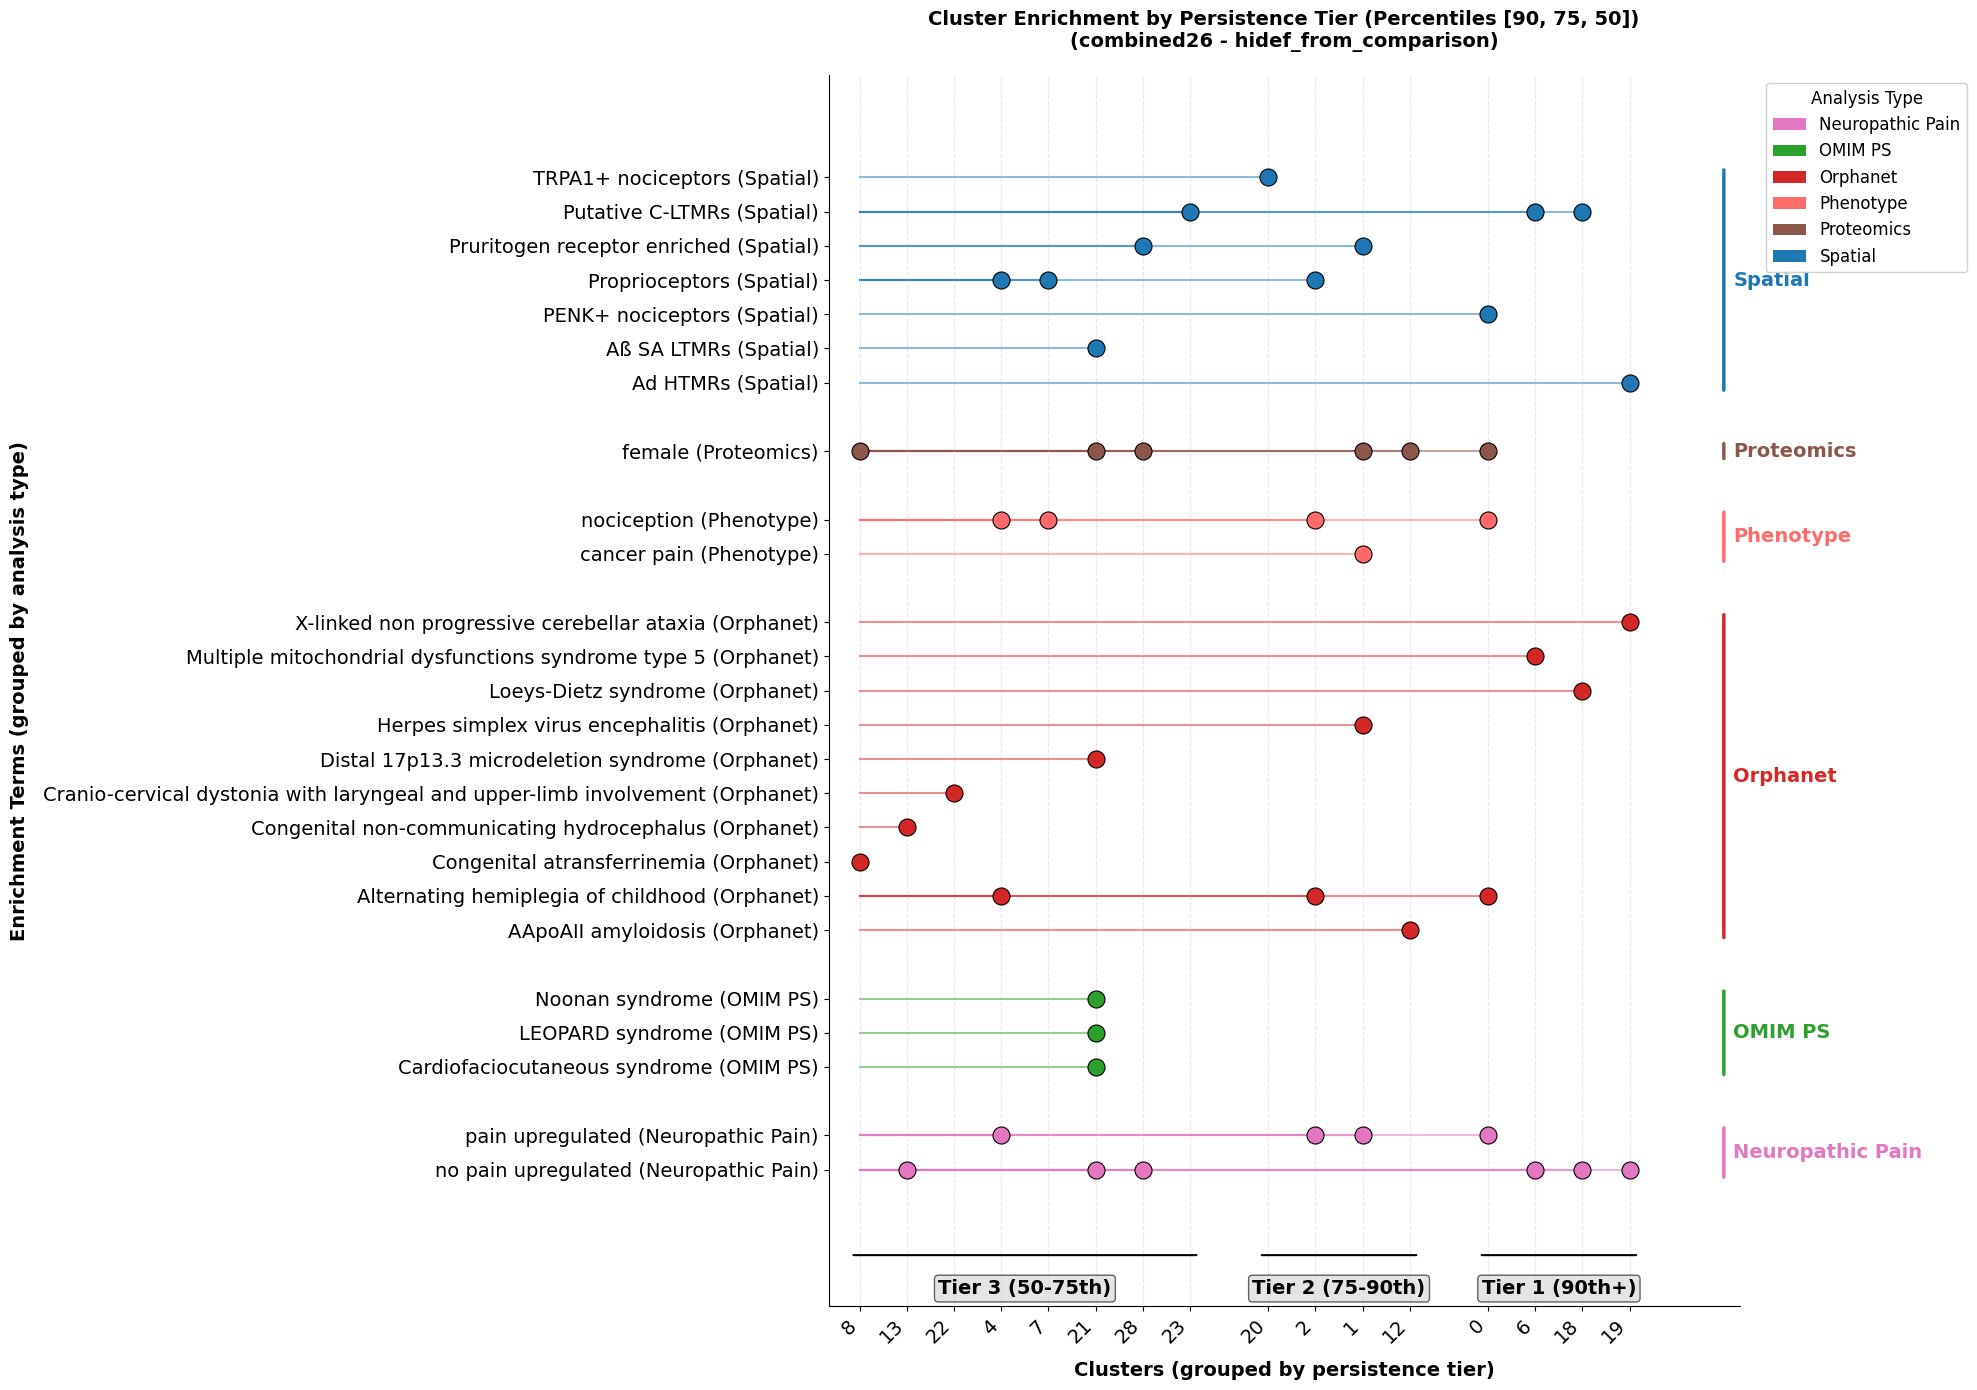


Plot saved to: plots/combined26/persistence_lollipop/persistence_lollipop_hidef_from_comparison_percentile_tiers.png
PDF saved to: plots/combined26/persistence_lollipop/persistence_lollipop_hidef_from_comparison_percentile_tiers.pdf

SUMMARY
Clusters in Tier 3 (50-75th): 8
Clusters in Tier 2 (75-90th): 4
Clusters in Tier 1 (90th+): 4


True

In [7]:

output_dir = './output'
ppi_source = 'combined26'

create_persistence_lollipop_plot(
    output_dir=output_dir,
    ppi_source=ppi_source,
    analysis_types=['neuropathic_pain', 'omim_ps',
                    'orphanet_enrichr', 
                    'phenotype', 'proteomics', 'spatial'],
    cluster_type='hidef_from_comparison',
    significance_threshold=0.05,
    figsize=(20, 14),
    min_cluster_size=10
)